In [11]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


first, load and store the data so we can
play with it

In [12]:
all_data = {}
label_strings = {}
colors = {}
for file_name,label_str,thisT, this_color in [
#     ('240226_TEMPOSO4_C10_W3_run1.DSC','$w_0$=3 cooling', 293,'blue'),
#     ('240226_TEMPOSO4_C10_W3_run2.DSC','$w_0$=3 heating',293,'green'),
    ('240226_TEMPOSO4_C10_W20_run1.DSC','$w_0$=20 cooling',293,'orange'),
#     ('240226_TEMPOSO4_C10_W20_run2.DSC','$w_0$=20 heating',293,'red'),
    ]:
    d = find_file(file_name,
            exp_type='francklab_esr/romana')
    d.shape ##RS
    d.chunk_auto("harmonic", "harmonic") #RS
    d.shape ##RS
    d = d["harmonic", 0]["phase", 0] #RS
    print("what is my shape?",d.shape)
    d.sort('Temperature')
    d = d["Temperature":thisT] ## RS
    print("what is my shape? 2",d.shape)
    label_strings[file_name] = label_str
    colors[file_name] = this_color
    try:
        d.getaxis('harmonic')
        print("Harmonics found...")
        harmonics = True  
        d_selected = d['harmonic',0]
        d_selected2 = d['harmonic',0]
    except ValueError:
        harmonics = False
        print("Harmonics not found...")
        d_selected = d
        d_selected2 = d
    try:
        d.getaxis("'Time'")
        print("Time axis found...")
        time_resolved = True
        d_selected = d_selected["'Time'",0]
        d_selected2 = d_selected2["'Time'",-1]
    except ValueError:
        time_resolved = False
        print("Time axis not found...")
        d_selected = d_selected
    d_selected -= d_selected['$B_0$',0]
    if file_name == '220329_TEMPOSO4_RM3_H2O.DSC':
        reference_data = d_selected.C
    else:
        d_selected.setaxis('$B_0$', lambda b: b - 56.)
    all_data[file_name] = d_selected

what is my shape? [(1024, '$B_0$'), (13, 'Temperature')]
what is my shape? 2 [(1024, '$B_0$')]
Harmonics not found...
Time axis not found...


Now, go ahead and plot them

[(1024, '$B_0$')]
3360.0
[(1024, '$B_0$')]
3375.0
[(1024, '$B_0$')]
1: slice peak A
2: slice peak B
3: slice peak C



c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)
c:\users\roman\git\pyspecdata\pyspecdata\core.py:987: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  retval = myplotfunc(*plotargs,**kwargs)


ValueError: the lower value of your slice (3470, 3400) on the "$B_0$" axis (which runs from 3229 to 3378.85) is higher than the highest value of the axis coordinates!

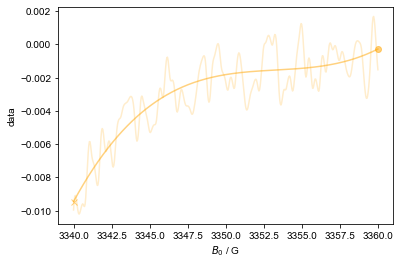

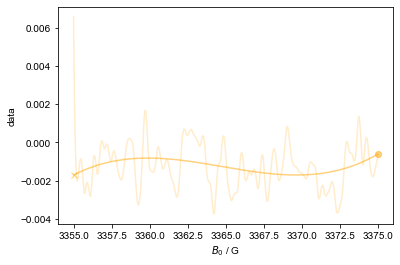

<Figure size 432x288 with 0 Axes>

In [14]:
x_counter = 0
j_counter = 0
correlation_time = {}
with figlist_var() as fl:
    for file_name in [
#             '240226_TEMPOSO4_C10_W3_run1.DSC',
#             '240226_TEMPOSO4_C10_W3_run2.DSC',
            '240226_TEMPOSO4_C10_W20_run1.DSC',
#             '240226_TEMPOSO4_C10_W20_run2.DSC',
            ]:
        this_color = colors[file_name]
        label_str = label_strings[file_name]
        d = all_data[file_name]
        d /= d.max().item()
        peak_data = {}
        for peak_range,peak_name in [
            ((3340,3360),'A'),
            ((3355,3375),'B'),
            ((3470,3400),'C'),
        ]:
            #### RS: 20 to 36. What's happening here?
            fl.next(f'slice peak {peak_name}')
            print(d.shape)
            peak = d['$B_0$':peak_range].spline_lambda()(linspace(*tuple(peak_range+(500,)))) ### ??
            plot(peak,c=this_color,alpha=0.2)
            peak = d['$B_0$':peak_range].spline_lambda(s_multiplier=1e-4)(linspace(*tuple(peak_range+(500,))))
            plot(peak,c=this_color,alpha=0.5) # overwrite with a smoothed one
            max_B0 = peak.C.argmax().item() ### ???
            min_B0 = peak.C.argmin()['$B_0$'] ### ???
            print(max_B0)
            peak_data[peak_name+'max']=peak['$B_0$':max_B0].item() ###???
            peak_data[peak_name+'min']=peak['$B_0$':min_B0].item() ###???
            peak_data[peak_name+'maxB0']=max_B0
            peak_data[peak_name+'minB0']=min_B0
            plot(peak_data[peak_name+'maxB0'],peak_data[peak_name+'max'],'o',c=this_color,alpha=0.5)
            plot(peak_data[peak_name+'minB0'],peak_data[peak_name+'min'],'x',c=this_color,alpha=0.5)
        fl.next('pub_fig',figsize=(6,6/(1+sqrt(5))*2))
        fl.plot(d+x_counter,alpha=0.8,color=this_color, human_units=False)
        plt.gca().text(
                3600,
                x_counter,
                label_str,
                transform = plt.gca().transData,
                va='bottom', ### RS???
                ha='left', ### RS???
                color=this_color,
                )
        annotate('%s'%label_str,(3.51,x_counter+0.1),color=this_color)
        x_counter += 1.1
        xlim(3300,3600)
        j_counter += 1
        print(eval("(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin)))",{'sqrt':sqrt},peak_data))
        tau_c = eval("6.51e-10*(BminB0-BmaxB0)*(sqrt((Bmax-Bmin)/(Amax-Amin))+sqrt((Bmax-Bmin)/(Cmax-Cmin))-2)",{'sqrt':sqrt},peak_data)
        print("correlation time is",tau_c)
        correlation_time[file_name] = tau_c 
    fl.next('pub_fig')
    plt.title('')
    plt.ylabel('')
    plt.gca().tick_params(left=False, bottom=True, right=False, top=False,
                          labelleft=False, labelbottom=True,
                          labelright=False)
    savefig('figures/RM_ESR_stack.pdf',
            transparent=True,
            bbox_inches='tight',
            pad_inches=0.1,
            dpi=400)

In [ ]:
print(r'''\begin{tabular}{cc}
$w_0$ & $\tau_c/\text{ns}$\\
\hline\hline
      '''
      +'\\\\\n'.join([label_strings[j].replace('$w_0$=','') +' & %0.2g'%(correlation_time[j]/1e-9) for j in [
            '221101_TEMPOSO4_w1_H2O_MarPrep_NovCap.DSC',
            '220329_TEMPOSO4_RM3_H2O.DSC',
            '221101_TEMPOSO4_RM5_H2O.DSC',
            '221101_TEMPOSO4_w10_H2O_MarPrep_NovCap.DSC',
            ]])
      +r'''\\ \hline
\end{tabular}
'''
      )

In [ ]:
R_h = 3.35e-9/2
T = 273+20
eta = 0.91e-3 # 1 cP = 1e-3 Pa*s
4*pi*R_h**3*eta/(3*k_B*T)/1e-9

In [ ]:
(0.29+1.1)/2

In [ ]:
3.35/2

In [ ]:
0.175+1.5